<a href="https://colab.research.google.com/github/Ariqq16/244107020161-mobile-course/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [13]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "images/training/"
	test_dir  = "images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

In [14]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

In [15]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

In [18]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

ValueError: Expected 2D array, got 1D array instead:
array=[].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [17]:
!unzip -q /content/sample_data/images.zip -d images/

replace images/__MACOSX/._images? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/._test? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/._training? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/test/._day? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/test/._night? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/training/._day? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/training/._night? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/images/test/day/20151102_122322.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/test/day/._20151102_122322.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/images/test/day/20151101_235039.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/__MACOSX/images/test/day/._20151101_235039.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace images/images/test/day

In [19]:
import os

# Perbarui jalur direktori karena hasil unzip berada di dalam folder 'images/images/'
train_dir = "images/images/training/"
test_dir  = "images/images/test/"

# Pastikan direktori tersebut ada
print("Train directory exists:", os.path.exists(train_dir))
print("Test directory exists:", os.path.exists(test_dir))

# Muat ulang dataset dengan direktori yang benar
train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah gambar training berhasil dimuat: {len(train_img)}")
print(f"Jumlah gambar test berhasil dimuat: {len(test_img)}")

Train directory exists: True
Test directory exists: True
Jumlah gambar training berhasil dimuat: 240
Jumlah gambar test berhasil dimuat: 160


In [20]:
# Jalankan kembali preprocessing untuk data yang baru dimuat
X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

# Ekstrak kembali fitur HOG
X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

# Lakukan normalisasi fitur (proses ini sekarang akan berjalan dengan lancar)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print("Fitur berhasil diekstrak dan dinormalisasi!")
print("Ukuran X_train_scaled:", X_train_scaled.shape)
print("Ukuran X_test_scaled:", X_test_scaled.shape)

Fitur berhasil diekstrak dan dinormalisasi!
Ukuran X_train_scaled: (240, 34596)
Ukuran X_test_scaled: (160, 34596)


In [21]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert label ke numpy array
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

Buat Model ANN

In [22]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 230ms/step - accuracy: 0.8125 - loss: 0.7237 - val_accuracy: 0.9583 - val_loss: 0.3786
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.9844 - loss: 0.0756 - val_accuracy: 0.9792 - val_loss: 0.2686
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.9948 - loss: 0.1094 - val_accuracy: 0.9792 - val_loss: 0.2645
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 1.0000 - loss: 1.6547e-04 - val_accuracy: 0.9792 - val_loss: 0.2657
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 8.5613e-05 - val_accuracy: 0.9792 - val_loss: 0.2791
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 1.0000 - loss: 9.7237e-06 - val_accuracy: 0.9792 - val_loss: 0.2902
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 1.0000 - loss: 5.3400e-06 - val_accuracy: 0.9792 - val_loss: 0.2969
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 1.0000 - loss: 3.2013e-06 - val_accuracy: 0.979

In [24]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8938 - loss: 1.3287
Akurasi Test: 0.893750011920929


In [25]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
              precision    recall  f1-score   support

           0       0.92      0.86      0.89        80
           1       0.87      0.93      0.90        80

    accuracy                           0.89       160
   macro avg       0.90      0.89      0.89       160
weighted avg       0.90      0.89      0.89       160

[[69 11]
 [ 6 74]]


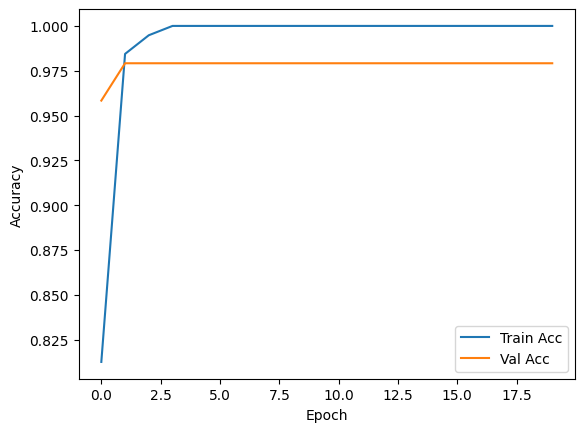

In [26]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

In [27]:
model.save('day_night_classifier_model.h5')